#  Comparative Study of Stacking-Based Hybrid and Machine Learning Models for Rainfall Prediction

## 1. Setup and Imports

In [ ]:
# core
import numpy as np
import pandas as pd
import itertools

# viz
import matplotlib.pyplot as plt
import seaborn as sns

# progress bars
from tqdm.auto import tqdm
from tqdm.keras import TqdmCallback

# preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder

# models
from sklearn.linear_model import LinearRegression
from sklearn.svm import LinearSVR
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# tuning
from sklearn.model_selection import GridSearchCV

# metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

# deep learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Bidirectional, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

import warnings
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
pd.set_option('display.max_columns', None)


## 2. GPU Check

In [ ]:
gpus = tf.config.list_physical_devices('GPU')
print("GPU available:", gpus)

USE_GPU = bool(gpus)

if USE_GPU:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"Using GPU: {gpus[0].name}")

    tf.keras.mixed_precision.set_global_policy('mixed_float16')  # faster GRU training on GPU
    print("Mixed precision enabled: mixed_float16")
else:
    print("No GPU detected — Runtime > Change runtime type > GPU, then restart session.")


GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using GPU: /physical_device:GPU:0
Mixed precision enabled: mixed_float16


## 3. Load Dataset

In [ ]:
# pip install python-calamine once per session (fast xlsx reader)
!pip install -q python-calamine

import os
import pandas as pd

from google.colab import files

uploaded = files.upload()
DATA_PATH = list(uploaded.keys())[0]

expected_size = len(uploaded[DATA_PATH])
actual_size = os.path.getsize(DATA_PATH)

print("Uploaded:", DATA_PATH)
print("Expected size:", expected_size, "bytes")
print("On-disk size:  ", actual_size, "bytes")

assert actual_size == expected_size, (
    f"Upload appears truncated ({actual_size} vs {expected_size} bytes). "
    "Re-run this cell and re-upload, or switch to the Google Drive option above."
)
print("Upload verified OK.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.2/920.2 kB 19.0 MB/s eta 0:00:00


Saving archive (2).zip to archive (2).zip
Uploaded: archive (2).zip
Expected size: 61241094 bytes
On-disk size:   61241094 bytes
Upload verified OK.


In [ ]:
import zipfile

# Cache location
PARQUET_CACHE = "/content/india_weather_rainfall_data.parquet"

# Load from cache if available
if os.path.exists(PARQUET_CACHE):
    print("Loading from Parquet cache...")
    df = pd.read_parquet(PARQUET_CACHE)

else:
    # If the uploaded file is a zip archive, extract the xlsx from it first
    if DATA_PATH.lower().endswith(".zip"):
        print("Uploaded file is a zip archive — extracting...")
        with zipfile.ZipFile(DATA_PATH, "r") as z:
            xlsx_names = [n for n in z.namelist() if n.lower().endswith(".xlsx")]
            assert xlsx_names, "No .xlsx file found inside the uploaded zip."
            EXTRACTED_PATH = z.extract(xlsx_names[0], path="/content/")
        print("Extracted:", EXTRACTED_PATH)
    else:
        EXTRACTED_PATH = DATA_PATH

    print("Reading Excel file...")

    try:
        df = pd.read_excel(EXTRACTED_PATH, engine="calamine")
    except Exception as e:
        print(f"calamine engine failed ({e}), falling back to openpyxl...")
        df = pd.read_excel(EXTRACTED_PATH, engine="openpyxl")

    df.to_parquet(PARQUET_CACHE, index=False)

print("Dataset shape:", df.shape)
display(df.head())

Uploaded file is a zip archive — extracting...
Extracted: /content/india_weather_rainfall_data.xlsx
Reading Excel file...
Dataset shape: (970339, 15)


,date_of_record,month,season,station_name,state,district,avg_temp,min_temp,max_temp,wind_speed,air_pressure,elevation,latitude,longitude,rainfall
0,2021-01-02,January,Winter,Gulmarg,JK,Baramulla,-2.2,-6.6,-0.8,2.2,1020.0,2652,34.05,74.4,0.1
1,2021-01-03,January,Winter,Gulmarg,JK,Baramulla,-3.6,-4.6,-1.8,3.7,1019.5,2652,34.05,74.4,4.4
2,2021-01-04,January,Winter,Gulmarg,JK,Baramulla,-3.0,-4.5,-1.1,2.1,1022.0,2652,34.05,74.4,2.3
3,2021-01-05,January,Winter,Gulmarg,JK,Baramulla,-3.3,-5.1,-1.2,2.8,1015.6,2652,34.05,74.4,35.0
4,2021-01-06,January,Winter,Gulmarg,JK,Baramulla,-3.9,-8.3,-1.0,3.4,1015.3,2652,34.05,74.4,25.5


## 4. Initial Data Overview

In [ ]:
df.head()

,date_of_record,month,season,station_name,state,district,avg_temp,min_temp,max_temp,wind_speed,air_pressure,elevation,latitude,longitude,rainfall
0,2021-01-02,January,Winter,Gulmarg,JK,Baramulla,-2.2,-6.6,-0.8,2.2,1020.0,2652,34.05,74.4,0.1
1,2021-01-03,January,Winter,Gulmarg,JK,Baramulla,-3.6,-4.6,-1.8,3.7,1019.5,2652,34.05,74.4,4.4
2,2021-01-04,January,Winter,Gulmarg,JK,Baramulla,-3.0,-4.5,-1.1,2.1,1022.0,2652,34.05,74.4,2.3
3,2021-01-05,January,Winter,Gulmarg,JK,Baramulla,-3.3,-5.1,-1.2,2.8,1015.6,2652,34.05,74.4,35.0
4,2021-01-06,January,Winter,Gulmarg,JK,Baramulla,-3.9,-8.3,-1.0,3.4,1015.3,2652,34.05,74.4,25.5


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 970339 entries, 0 to 970338
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   date_of_record  970339 non-null  datetime64[ns]
 1   month           970339 non-null  object        
 2   season          970339 non-null  object        
 3   station_name    970339 non-null  object        
 4   state           970339 non-null  object        
 5   district        970339 non-null  object        
 6   avg_temp        970339 non-null  float64       
 7   min_temp        926441 non-null  float64       
 8   max_temp        859741 non-null  float64       
 9   wind_speed      695895 non-null  float64       
 10  air_pressure    665675 non-null  float64       
 11  elevation       970339 non-null  int64         
 12  latitude        970339 non-null  float64       
 13  longitude       970339 non-null  float64       
 14  rainfall        712785 non-null  flo

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date_of_record,970339,NaN,NaN,NaN,2021-03-27 08:51:14.557655808,2015-01-01 00:00:00,2019-03-07 00:00:00,2021-11-09 00:00:00,2023-06-24 00:00:00,2025-02-10 00:00:00,NaN
month,970339,12,January,92905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,970339,4,Winter,333244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
station_name,970339,406,Srinagar,7388,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,970339,32,MH,98770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,970339,314,Visakhapatnam,13400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_temp,970339.0,NaN,NaN,NaN,25.661709,-10.4,23.1,26.7,29.1,43.4,5.438133
min_temp,926441.0,NaN,NaN,NaN,20.647342,-18.5,17.1,22.4,25.0,36.6,6.008171
max_temp,859741.0,NaN,NaN,NaN,31.195383,-5.6,28.5,31.6,34.4,87.0,5.464499
wind_speed,695895.0,NaN,NaN,NaN,9.432732,0.0,6.1,8.4,11.6,66.6,4.979263


In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
air_pressure,304664
wind_speed,274444
rainfall,257554
max_temp,110598
min_temp,43898
month,0
date_of_record,0
avg_temp,0
district,0
state,0


In [ ]:
df.nunique()

,0
date_of_record,3694
month,12
season,4
station_name,406
state,32
district,314
avg_temp,514
min_temp,494
max_temp,545
wind_speed,499


## 5. Advanced Data Cleaning

### 5.1 Drop Rows with Missing Target (rainfall)

In [ ]:
# rows without a target value can't be used for training or imputed without bias, so drop them
before = df.shape[0]
df = df.dropna(subset=['rainfall']).reset_index(drop=True)
after = df.shape[0]
print(f"Dropped {before - after} rows with missing target ({(before-after)/before*100:.2f}%)")
df.shape


Dropped 257554 rows with missing target (26.54%)


(712785, 15)

### 5.2 Missing Value Audit (Remaining Columns)

In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_report = pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct})
missing_report[missing_report['missing_count'] > 0].sort_values('missing_%', ascending=False)


,missing_count,missing_%
air_pressure,95595,13.411478
wind_speed,85128,11.943012
max_temp,34995,4.909615
min_temp,12131,1.701916


### 5.3 Impute Remaining Missing Values

In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()  # numeric feature columns
cat_cols = df.select_dtypes(include=['object']).columns.tolist()    # categorical feature columns
num_cols.remove('rainfall')  # target already clean, exclude from feature imputation loop

for c in tqdm(num_cols, desc="Imputing numeric columns"):
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].median())  # median is robust to outliers

for c in tqdm(cat_cols, desc="Imputing categorical columns"):
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].mode()[0])  # fill with the most frequent category

df.isnull().sum().sum()  # sanity check: should be 0


Imputing numeric columns:   0%|          | 0/8 [00:00<?, ?it/s]

Imputing categorical columns:   0%|          | 0/5 [00:00<?, ?it/s]

np.int64(0)

### 5.4 Remove Duplicate Records

In [ ]:
before = df.shape[0]
df.drop_duplicates(inplace=True)          # remove exact duplicate rows
df.reset_index(drop=True, inplace=True)   # re-index after dropping rows
print(f"Removed {before - df.shape[0]} duplicate rows")
df.shape


Removed 0 duplicate rows


(712785, 15)

### 5.5 Domain Validity Checks

In [ ]:
# rainfall, wind speed and elevation cannot physically be negative
print("Negative rainfall rows:", (df['rainfall'] < 0).sum())
print("Negative wind_speed rows:", (df['wind_speed'] < 0).sum())
print("Negative elevation rows:", (df['elevation'] < 0).sum())

# min_temp should not exceed max_temp
inconsistent_temp = (df['min_temp'] > df['max_temp']).sum()
print("Rows where min_temp > max_temp:", inconsistent_temp)

df = df[df['rainfall'] >= 0]
df = df[df['min_temp'] <= df['max_temp']]
df.reset_index(drop=True, inplace=True)
df.shape


Negative rainfall rows: 0
Negative wind_speed rows: 0
Negative elevation rows: 0
Rows where min_temp > max_temp: 445


(712340, 15)

### 5.6 Outlier Detection and Treatment (IQR Capping)

In [ ]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k*iqr, q3 + k*iqr  # lower/upper fence for outlier detection

outlier_cols = ['avg_temp', 'min_temp', 'max_temp', 'wind_speed', 'air_pressure', 'rainfall']
outlier_summary = {}

for c in tqdm(outlier_cols, desc="Capping outliers"):
    lower, upper = iqr_bounds(df[c])
    n_outliers = ((df[c] < lower) | (df[c] > upper)).sum()
    outlier_summary[c] = n_outliers
    df[c] = df[c].clip(lower, upper)  # cap instead of drop, to keep the row count intact

pd.Series(outlier_summary, name='outliers_capped')


Capping outliers:   0%|          | 0/6 [00:00<?, ?it/s]

,outliers_capped
avg_temp,33740
min_temp,20143
max_temp,32442
wind_speed,40447
air_pressure,7831
rainfall,102814


### 5.7 Data Type Corrections

In [ ]:
df['date_of_record'] = pd.to_datetime(df['date_of_record'])       # parse date strings
df = df.sort_values('date_of_record').reset_index(drop=True)      # chronological order for time-based split later
df.dtypes


,0
date_of_record,datetime64[ns]
month,object
season,object
station_name,object
state,object
district,object
avg_temp,float64
min_temp,float64
max_temp,float64
wind_speed,float64


### 5.8 Encode Categorical Variables

In [ ]:
le_dict = {}
for c in tqdm(['month', 'season', 'station_name', 'state', 'district'], desc="Encoding categoricals"):
    le = LabelEncoder()
    df[c + '_enc'] = le.fit_transform(df[c])  # add a numeric-encoded copy, keep the original column
    le_dict[c] = le  # keep encoders in case we need to inverse_transform later

df[['month', 'month_enc', 'season', 'season_enc']].head()


Encoding categoricals:   0%|          | 0/5 [00:00<?, ?it/s]

,month,month_enc,season,season_enc
0,January,4,Winter,3
1,January,4,Winter,3
2,January,4,Winter,3
3,January,4,Winter,3
4,January,4,Winter,3


### 5.9 Final Cleaned Dataset Summary

In [ ]:
print("Final shape:", df.shape)
print("Date range:", df['date_of_record'].min(), "to", df['date_of_record'].max())
print("Stations:", df['station_name'].nunique(), "| States:", df['state'].nunique())
df.describe().T


Final shape: (712340, 20)
Date range: 2015-01-01 00:00:00 to 2025-02-10 00:00:00
Stations: 406 | States: 32


,count,mean,min,25%,50%,75%,max,std
date_of_record,712340,2022-04-28 20:18:57.137883648,2015-01-01 00:00:00,2021-07-02 00:00:00,2022-09-20 00:00:00,2023-11-28 00:00:00,2025-02-10 00:00:00,NaN
avg_temp,712340.0,25.623694,14.55,23.1,26.6,28.8,37.35,4.842836
min_temp,712340.0,20.959264,7.0,17.8,22.6,25.0,35.8,5.513057
max_temp,712340.0,31.018293,20.0,28.4,31.2,34.0,42.4,4.823985
wind_speed,712340.0,9.224131,0.0,6.5,8.5,11.2,18.25,3.932406
air_pressure,712340.0,1009.423922,996.95,1006.4,1009.7,1012.7,1022.15,4.869127
elevation,712340.0,310.220357,0.0,16.0,140.0,458.0,2652.0,430.927493
latitude,712340.0,20.75192,7.9833,15.4833,21.65,25.6,34.0833,6.409422
longitude,712340.0,79.679706,68.85,75.6333,78.0833,83.2245,95.3833,5.968571
rainfall,712340.0,2.446747,0.0,0.0,0.0,4.0,10.0,3.74748


### 5.10 Downcast Dtypes for Speed and Memory

In [ ]:
# float64 -> float32 and int64 -> int32 to cut memory and speed up sklearn/numpy/keras ops
before_mem = df.memory_usage(deep=True).sum() / 1e6

float_cols = df.select_dtypes(include=['float64']).columns
int_cols = df.select_dtypes(include=['int64']).columns

df[float_cols] = df[float_cols].astype('float32')
df[int_cols] = df[int_cols].astype('int32')

after_mem = df.memory_usage(deep=True).sum() / 1e6
print(f"Memory usage: {before_mem:.1f} MB -> {after_mem:.1f} MB")


Memory usage: 284.9 MB -> 245.0 MB


## 6. Exploratory Data Analysis (EDA)

### 6.1 Target Variable Distribution

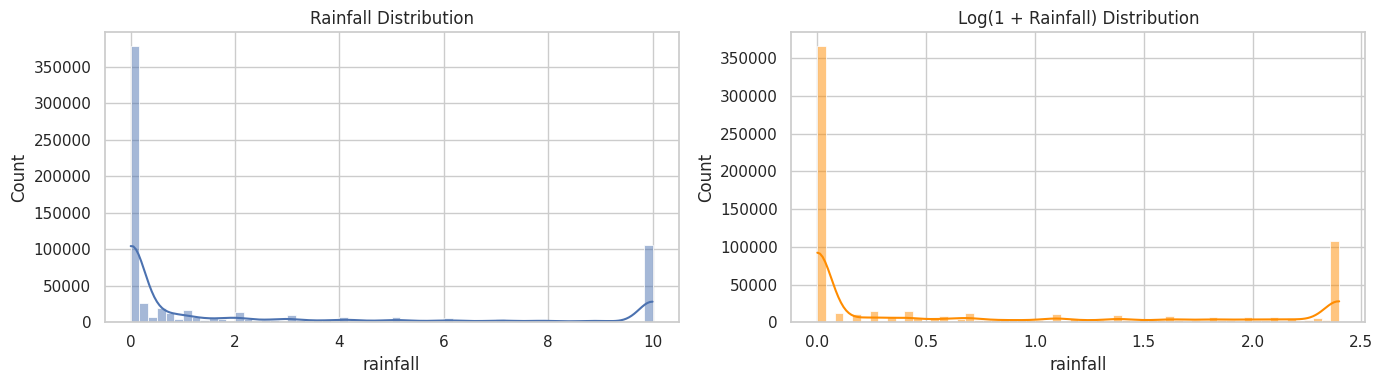

Skewness: 1.246
Kurtosis: -0.153


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))
sns.histplot(df['rainfall'], bins=60, kde=True, ax=axes[0])
axes[0].set_title("Rainfall Distribution")
sns.histplot(np.log1p(df['rainfall']), bins=60, kde=True, ax=axes[1], color='darkorange')  # log1p to visualize the right-skewed tail
axes[1].set_title("Log(1 + Rainfall) Distribution")
plt.tight_layout()
plt.show()

print("Skewness:", df['rainfall'].skew().round(3))  # >0 means a right-skewed distribution
print("Kurtosis:", df['rainfall'].kurt().round(3))   # >0 means heavier tails than a normal distribution


### 6.2 Box Plots of Key Numeric Features

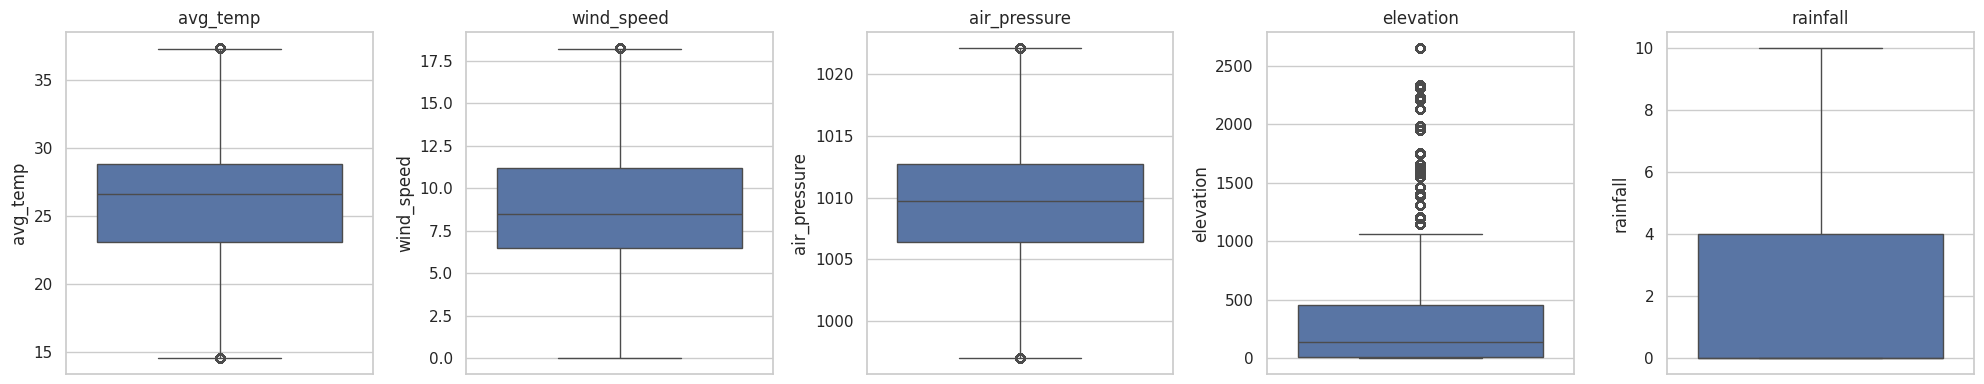

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20,4))
for ax, col in zip(axes, ['avg_temp', 'wind_speed', 'air_pressure', 'elevation', 'rainfall']):
    sns.boxplot(y=df[col], ax=ax)  # visual check for any remaining outliers post-capping
    ax.set_title(col)
plt.tight_layout()
plt.show()


### 6.3 Correlation Heatmap

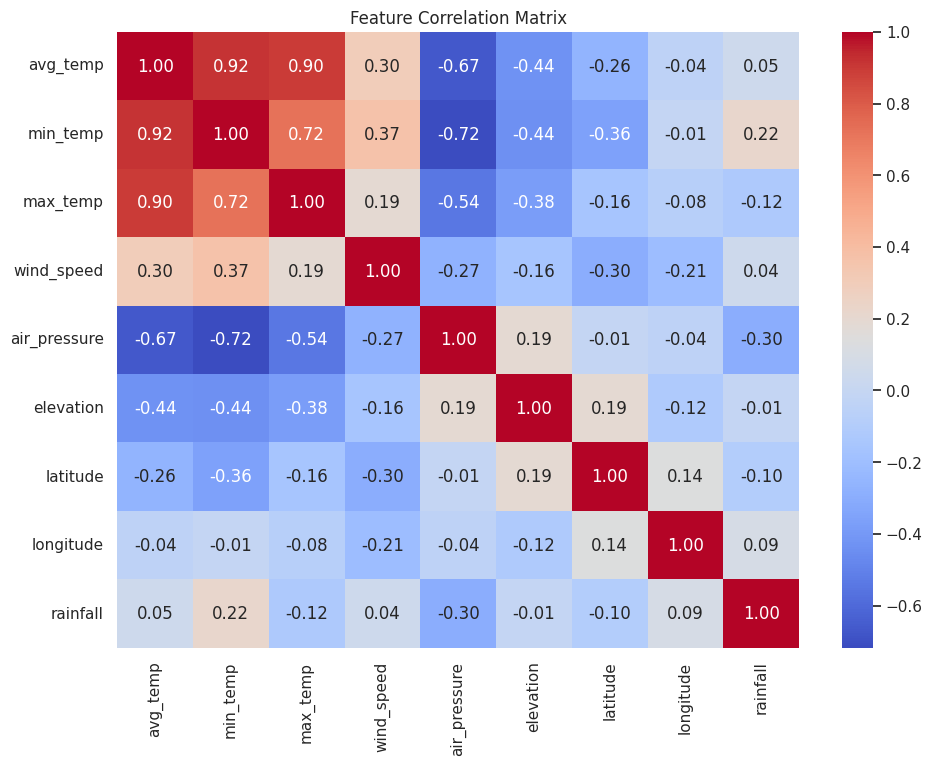

,rainfall
rainfall,1.000000
min_temp,0.218705
longitude,0.092240
avg_temp,0.045107
wind_speed,0.041325
elevation,-0.006943
latitude,-0.097614
max_temp,-0.122848
air_pressure,-0.298792


In [ ]:
plt.figure(figsize=(11,8))
corr = df[num_cols + ['rainfall']].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Matrix")
plt.show()

corr['rainfall'].sort_values(ascending=False)  # rank features by linear correlation with the target


### 6.4 Pairwise Relationships with Rainfall

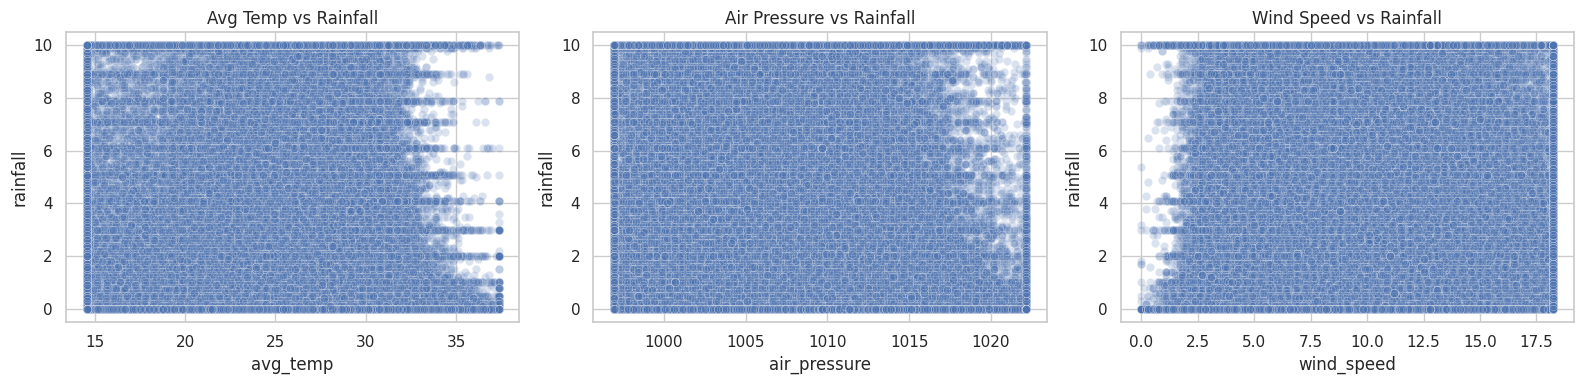

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
sns.scatterplot(x=df['avg_temp'], y=df['rainfall'], alpha=0.2, ax=axes[0])      # low alpha to reveal density in overplotted regions
sns.scatterplot(x=df['air_pressure'], y=df['rainfall'], alpha=0.2, ax=axes[1])
sns.scatterplot(x=df['wind_speed'], y=df['rainfall'], alpha=0.2, ax=axes[2])
axes[0].set_title("Avg Temp vs Rainfall")
axes[1].set_title("Air Pressure vs Rainfall")
axes[2].set_title("Wind Speed vs Rainfall")
plt.tight_layout()
plt.show()


### 6.5 Seasonal Rainfall Trend

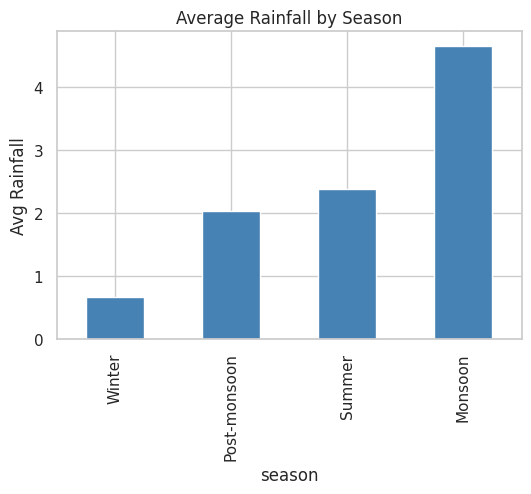

In [ ]:
season_avg = df.groupby('season')['rainfall'].mean().sort_values()  # mean rainfall per season, ascending
season_avg.plot(kind='bar', figsize=(6,4), color='steelblue')
plt.ylabel("Avg Rainfall")
plt.title("Average Rainfall by Season")
plt.show()


### 6.6 Monthly Rainfall Trend

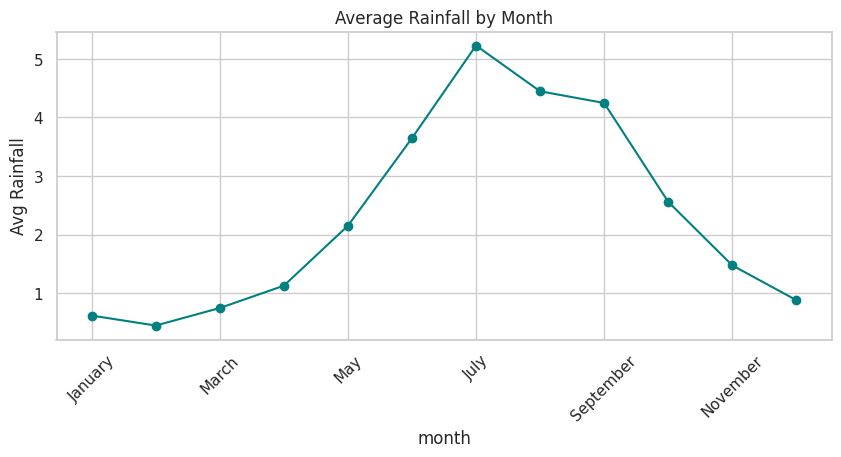

In [ ]:
month_avg = df.groupby('month')['rainfall'].mean().reindex(
    ['January','February','March','April','May','June','July','August','September','October','November','December']
)  # reindex to force calendar order instead of alphabetical
month_avg.plot(kind='line', marker='o', figsize=(10,4), color='teal')
plt.ylabel("Avg Rainfall")
plt.title("Average Rainfall by Month")
plt.xticks(rotation=45)
plt.show()


### 6.7 State-wise Rainfall

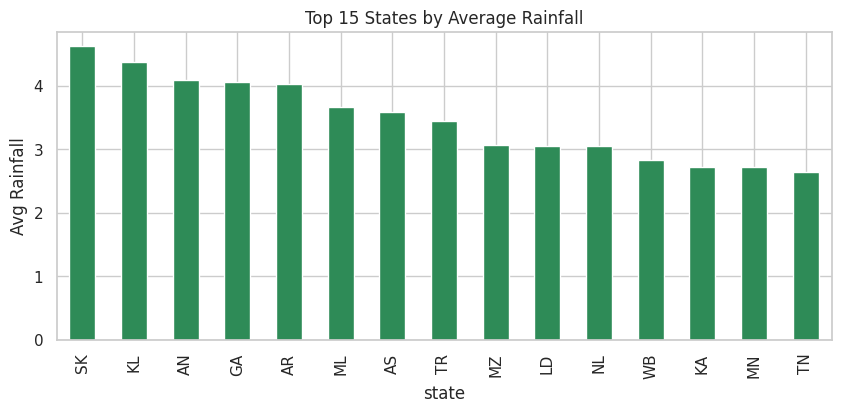

In [ ]:
state_avg = df.groupby('state')['rainfall'].mean().sort_values(ascending=False).head(15)  # top 15 wettest states
state_avg.plot(kind='bar', figsize=(10,4), color='seagreen')
plt.ylabel("Avg Rainfall")
plt.title("Top 15 States by Average Rainfall")
plt.show()


### 6.8 Rainfall Trend Over Time (Yearly)

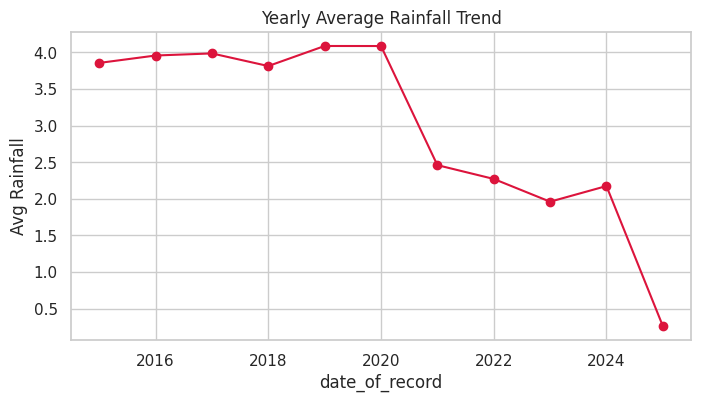

In [ ]:
yearly = df.groupby(df['date_of_record'].dt.year)['rainfall'].mean()  # average rainfall per calendar year
yearly.plot(kind='line', marker='o', figsize=(8,4), color='crimson')
plt.ylabel("Avg Rainfall")
plt.title("Yearly Average Rainfall Trend")
plt.show()


### 6.9 Geographic Distribution of Rainfall

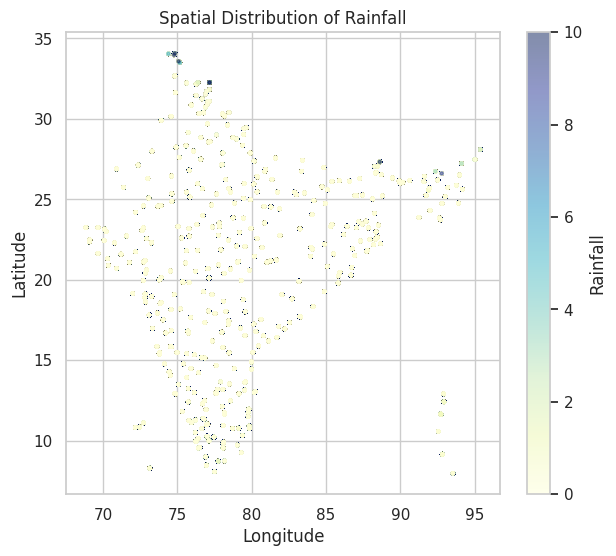

In [ ]:
plt.figure(figsize=(7,6))
sc = plt.scatter(df['longitude'], df['latitude'], c=df['rainfall'], cmap='YlGnBu', s=5, alpha=0.5)  # color-coded by rainfall
plt.colorbar(sc, label='Rainfall')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Rainfall")
plt.show()


## 7. Feature Engineering

### 7.1 Date-Based Features

In [ ]:
df['year'] = df['date_of_record'].dt.year            # captures long-term/inter-annual trend
df['day_of_year'] = df['date_of_record'].dt.dayofyear  # captures seasonality within a year


### 7.2 Feature Selection

In [ ]:
feature_cols = ['month_enc', 'season_enc', 'station_name_enc', 'state_enc', 'district_enc',
                'avg_temp', 'min_temp', 'max_temp', 'wind_speed', 'air_pressure',
                'elevation', 'latitude', 'longitude', 'year', 'day_of_year']
target_col = 'rainfall'

X = df[feature_cols].values  # feature matrix
y = df[target_col].values    # target vector
X.shape, y.shape


((712340, 15), (712340,))

### 7.3 Feature Scaling

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype('float32')  # zero mean, unit variance — needed for SVR/GRU convergence


## 8. Dataset Splitting (Chronological 70:15:15)

In [ ]:
n = len(df)
train_end = int(n*0.70)  # first 70% of dates -> train
val_end = int(n*0.85)    # next 15% -> validation, remaining 15% -> test

X_train, y_train = X_scaled[:train_end], y[:train_end]
X_val, y_val = X_scaled[train_end:val_end], y[train_end:val_end]
X_test, y_test = X_scaled[val_end:], y[val_end:]  # chronological split (no shuffling) to avoid lookahead leakage

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)


Train: (498637, 15) Val: (106852, 15) Test: (106851, 15)


## 9. Evaluation Function

In [ ]:
def smape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2
    denom = np.where(denom == 0, 1, denom)
    return np.mean(np.abs(y_true - y_pred) / denom) * 100

def evaluate_model(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    smape_val = smape(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'sMAPE': smape_val, 'R2': r2}

results = []

## 10. Hyperparameter Tuning Setup


In [ ]:
# each baseline model below is tuned with sklearn's GridSearchCV (3-fold CV, MAE scoring).
# GridSearchCV has no built-in progress bar, so this context manager patches joblib to
# update a tqdm bar as each fold/candidate fit completes.
import contextlib
import joblib

@contextlib.contextmanager
def tqdm_joblib(tqdm_object):
    class TqdmBatchCompletionCallback(joblib.parallel.BatchCompletionCallBack):
        def __call__(self, *args, **kwargs):
            tqdm_object.update(n=self.batch_size)
            return super().__call__(*args, **kwargs)

    old_callback = joblib.parallel.BatchCompletionCallBack
    joblib.parallel.BatchCompletionCallBack = TqdmBatchCompletionCallback
    try:
        yield tqdm_object
    finally:
        joblib.parallel.BatchCompletionCallBack = old_callback
        tqdm_object.close()


## 11. Baseline Model 1 - Linear Regression

In [ ]:
lr_params = {'fit_intercept': [True, False], 'positive': [True, False]}
lr_grid = GridSearchCV(LinearRegression(), lr_params, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)

n_fits = len(list(itertools.product(*lr_params.values()))) * 3  # candidates x folds
with tqdm_joblib(tqdm(desc="Linear Regression grid search", total=n_fits)):
    lr_grid.fit(X_train, y_train)          # search + refit on the full training set
best_lr = lr_grid.best_estimator_      # best model found by the search

pred_lr = best_lr.predict(X_test)
results.append(evaluate_model(y_test, pred_lr, 'Linear Regression'))
print("Best params:", lr_grid.best_params_)
results[-1]


Linear Regression grid search:   0%|          | 0/12 [00:00<?, ?it/s]

Best params: {'fit_intercept': True, 'positive': False}


{'Model': 'Linear Regression',
 'MAE': 2.3665502071380615,
 'MSE': 9.736093521118164,
 'RMSE': np.float64(3.1202713858121642),
 'sMAPE': np.float32(140.5986),
 'R2': 0.348480761051178}

## 12. Baseline Model 2 - Support Vector Regression (SVR)

In [ ]:
# LinearSVR (liblinear) instead of RBF-kernel SVR — RBF scales too poorly for ~680k rows
svr_params = {'C': [1, 10], 'epsilon': [0.1, 0.2]}
svr_grid = GridSearchCV(LinearSVR(max_iter=5000, random_state=42), svr_params, cv=3,
                         scoring='neg_mean_absolute_error', n_jobs=-1)

n_fits = len(list(itertools.product(*svr_params.values()))) * 3
with tqdm_joblib(tqdm(desc="SVR grid search", total=n_fits)):
    svr_grid.fit(X_train, y_train)
best_svr = svr_grid.best_estimator_

pred_svr = best_svr.predict(X_test)
results.append(evaluate_model(y_test, pred_svr, 'SVR'))
print("Best params:", svr_grid.best_params_)
results[-1]


SVR grid search:   0%|          | 0/12 [00:00<?, ?it/s]

Best params: {'C': 10, 'epsilon': 0.1}


{'Model': 'SVR',
 'MAE': 2.3221726206317252,
 'MSE': 12.898894280660251,
 'RMSE': np.float64(3.591503067054273),
 'sMAPE': np.float64(148.46690204670304),
 'R2': 0.13683257821083605}

## 13. Baseline Model 3 - Random Forest Regression

In [ ]:
# max_samples=0.5 bootstraps each tree on half the rows to speed up training on ~680k rows
rf_params = {'n_estimators': [100, 200], 'max_depth': [10, 20]}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1, max_samples=0.5),
                        rf_params, cv=3, scoring='neg_mean_absolute_error')

n_fits = len(list(itertools.product(*rf_params.values()))) * 3
with tqdm_joblib(tqdm(desc="Random Forest grid search", total=n_fits)):
    rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_

pred_rf = best_rf.predict(X_test)
results.append(evaluate_model(y_test, pred_rf, 'Random Forest'))
print("Best params:", rf_grid.best_params_)
results[-1]


Random Forest grid search:   0%|          | 0/12 [00:00<?, ?it/s]

Best params: {'max_depth': 20, 'n_estimators': 200}


{'Model': 'Random Forest',
 'MAE': 1.7327293129111632,
 'MSE': 6.702185134759105,
 'RMSE': np.float64(2.588857882302369),
 'sMAPE': np.float64(133.15271004190404),
 'R2': 0.5515035833887338}

## 14. Baseline Model 4 - XGBoost Regression

In [ ]:
# tree_method='hist' is XGBoost's fast histogram algorithm; device='cuda' uses the GPU if available
xgb_device = 'cuda' if USE_GPU else 'cpu'

xgb_params = {'n_estimators': [100, 200], 'max_depth': [4, 6], 'learning_rate': [0.05, 0.1]}
xgb_grid = GridSearchCV(XGBRegressor(random_state=42, tree_method='hist', device=xgb_device),
                         xgb_params, cv=3, scoring='neg_mean_absolute_error')

n_fits = len(list(itertools.product(*xgb_params.values()))) * 3
with tqdm_joblib(tqdm(desc="XGBoost grid search", total=n_fits)):
    xgb_grid.fit(X_train, y_train)
best_xgb = xgb_grid.best_estimator_

pred_xgb = best_xgb.predict(X_test)
results.append(evaluate_model(y_test, pred_xgb, 'XGBoost'))
print("Best params:", xgb_grid.best_params_)
results[-1]


XGBoost grid search:   0%|          | 0/24 [00:00<?, ?it/s]

Best params: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200}


{'Model': 'XGBoost',
 'MAE': 1.763704538345337,
 'MSE': 6.806568145751953,
 'RMSE': np.float64(2.6089400425751363),
 'sMAPE': np.float32(134.85852),
 'R2': 0.5445185303688049}

## 15. Proposed Stacking-Based Hybrid Model ( GRU + XGBoost -> Linear Regression Meta-Model)

### 15.1 Reshape Data for GRU (Sequence Input)

In [ ]:
timesteps = 1  # single step, features as sequence dimension
X_train_gru = X_train.reshape((X_train.shape[0], timesteps, X_train.shape[1]))  # GRU expects (samples, timesteps, features)
X_val_gru = X_val.reshape((X_val.shape[0], timesteps, X_val.shape[1]))
X_test_gru = X_test.reshape((X_test.shape[0], timesteps, X_test.shape[1]))


### 15.2  GRU Architecture Builder

In [ ]:
# stacked / bidirectional GRU with batch norm, dropout, and L2 regularization
# Dense output kept in float32 since float16 loss is unstable under mixed precision
def build_gru(units=64, layers=2, dropout=0.2, l2_reg=1e-4, bidirectional=False, learning_rate=1e-3):
    model = Sequential()
    for i in range(layers):
        return_seq = i < layers - 1
        gru_layer = GRU(units, activation='tanh', return_sequences=return_seq,
                         kernel_regularizer=l2(l2_reg))
        if bidirectional:
            gru_layer = Bidirectional(gru_layer)
        if i == 0:
            model.add(tf.keras.Input(shape=(timesteps, X_train.shape[1])))
        model.add(gru_layer)
        model.add(BatchNormalization())
        model.add(Dropout(dropout))

    model.add(Dense(32, activation='relu', kernel_regularizer=l2(l2_reg)))
    model.add(Dense(1, dtype='float32'))

    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mse', metrics=['mae'])
    return model


### 15.3 Grid Search on GRU Hyperparameters

In [ ]:
# GridSearchCV doesn't work directly on Keras models, so this loop searches manually
gru_param_grid = {
    'units': [64, 128],
    'layers': [1, 2],
    'dropout': [0.2, 0.3],
    'bidirectional': [False, True],
    'learning_rate': [1e-3, 5e-4],
}

param_names = list(gru_param_grid.keys())
param_combos = list(itertools.product(*gru_param_grid.values()))
print(f"Total combinations to search: {len(param_combos)}")

gru_search_results = []
search_epochs = 5
search_batch_size = 1024 if USE_GPU else 256

for combo in tqdm(param_combos, desc="GRU grid search"):
    params = dict(zip(param_names, combo))

    candidate = build_gru(**params)
    es = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

    hist = candidate.fit(
        X_train_gru, y_train,
        validation_data=(X_val_gru, y_val),
        epochs=search_epochs,
        batch_size=search_batch_size,
        verbose=0,
        callbacks=[es]
    )

    val_mae = min(hist.history['val_mae'])
    gru_search_results.append({**params, 'val_mae': val_mae})

gru_search_df = pd.DataFrame(gru_search_results).sort_values('val_mae').reset_index(drop=True)
gru_search_df


Total combinations to search: 32


GRU grid search:   0%|          | 0/32 [00:00<?, ?it/s]

,units,layers,dropout,bidirectional,learning_rate,val_mae
0,128,2,0.3,True,0.0010,0.963444
1,64,2,0.3,True,0.0010,0.989351
2,128,2,0.3,False,0.0010,0.997436
3,64,2,0.3,False,0.0010,0.998385
4,64,2,0.3,False,0.0005,1.002069
5,128,2,0.2,True,0.0010,1.007746
6,128,2,0.2,False,0.0010,1.017758
7,64,2,0.3,True,0.0005,1.017876
8,64,2,0.2,False,0.0010,1.025331
9,64,2,0.2,True,0.0010,1.026727


### 15.4 Select Best GRU Configuration

In [ ]:
best_gru_params = gru_search_df.iloc[0][param_names].to_dict()  # row with lowest val_mae
# cast numeric params back to correct types after DataFrame round-trip
best_gru_params['units'] = int(best_gru_params['units'])
best_gru_params['layers'] = int(best_gru_params['layers'])
best_gru_params['dropout'] = float(best_gru_params['dropout'])
best_gru_params['bidirectional'] = bool(best_gru_params['bidirectional'])
best_gru_params['learning_rate'] = float(best_gru_params['learning_rate'])
print("Best GRU config:", best_gru_params)


Best GRU config: {'units': 128, 'layers': 2, 'dropout': 0.3, 'bidirectional': True, 'learning_rate': 0.001}


### 15.5 Train Final GRU Base Model (Full Budget, with Progress Bar)

In [ ]:
gru_model = build_gru(**best_gru_params)
gru_model.summary()

final_batch_size = 1024 if USE_GPU else 256

callbacks = [
    TqdmCallback(verbose=1),                                                          # progress bar
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),         # stop when val loss stalls
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)        # halve LR on plateau
]

history = gru_model.fit(
    X_train_gru, y_train,
    validation_data=(X_val_gru, y_val),
    epochs=50,               # upper bound; EarlyStopping will typically stop sooner
    batch_size=final_batch_size,
    verbose=0,
    callbacks=callbacks
)


Model: "sequential_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_24                │ (None, 1, 256)         │       111,360 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_48          │ (None, 1, 256)         │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_48 (Dropout)            │ (None, 1, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_25                │ (None, 256)            │       296,448 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_49          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_49 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 418,113 (1.59 MB)

 Trainable params: 417,089 (1.59 MB)

 Non-trainable params: 1,024 (4.00 KB)

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

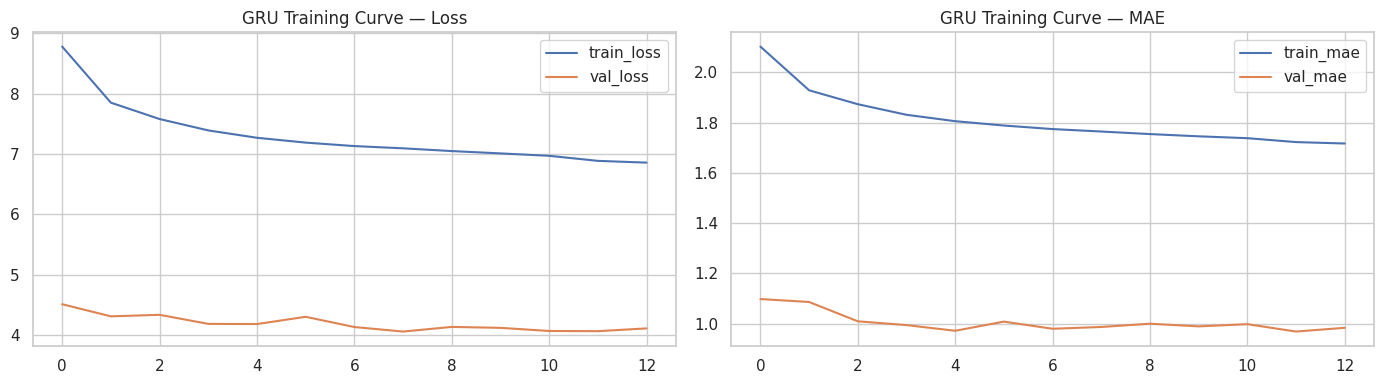

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))
axes[0].plot(history.history['loss'], label='train_loss')
axes[0].plot(history.history['val_loss'], label='val_loss')
axes[0].set_title("GRU Training Curve — Loss")
axes[0].legend()

axes[1].plot(history.history['mae'], label='train_mae')
axes[1].plot(history.history['val_mae'], label='val_mae')
axes[1].set_title("GRU Training Curve — MAE")
axes[1].legend()
plt.tight_layout()
plt.show()  # look for widening gap between train/val curves as a sign of overfitting


### 15.6 Train XGBoost Base Model

In [ ]:
# reuse the already-tuned XGBoost model rather than retraining an identical one
xgb_base = best_xgb


### 15.7 Generate Base Model Predictions (Stacking Features)

In [ ]:
gru_train_pred = gru_model.predict(X_train_gru, verbose=1).flatten()
gru_val_pred = gru_model.predict(X_val_gru, verbose=1).flatten()
gru_test_pred = gru_model.predict(X_test_gru, verbose=1).flatten()

xgb_train_pred = xgb_base.predict(X_train)
xgb_val_pred = xgb_base.predict(X_val)
xgb_test_pred = xgb_base.predict(X_test)

# stack base-model predictions as features for the meta-model
meta_X_train = np.column_stack([gru_train_pred, xgb_train_pred])
meta_X_val = np.column_stack([gru_val_pred, xgb_val_pred])
meta_X_test = np.column_stack([gru_test_pred, xgb_test_pred])


15583/15583 ━━━━━━━━━━━━━━━━━━━━ 48s 3ms/step
3340/3340 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step
3340/3340 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step


### 15.8 Train Meta-Model (Linear Regression)

In [ ]:
meta_model = LinearRegression()
meta_model.fit(meta_X_train, y_train)          # learns how to weight the two base models' predictions
pred_stack = meta_model.predict(meta_X_test)
results.append(evaluate_model(y_test, pred_stack, 'Proposed Stacking (GRU+XGBoost+LR)'))
results[-1]


{'Model': 'Proposed Stacking (GRU+XGBoost+LR)',
 'MAE': 1.6838287115097046,
 'MSE': 6.47175931930542,
 'RMSE': np.float64(2.5439652747837225),
 'sMAPE': np.float32(133.64435),
 'R2': 0.5669232606887817}

## 16. Model Comparison

In [ ]:
results_df = pd.DataFrame(results).sort_values('RMSE')  # lower RMSE = better, so ascending sort ranks best first
results_df


,Model,MAE,MSE,RMSE,sMAPE,R2
4,Proposed Stacking (GRU+XGBoost+LR),1.683829,6.471759,2.543965,133.644348,0.566923
2,Random Forest,1.732729,6.702185,2.588858,133.152710,0.551504
3,XGBoost,1.763705,6.806568,2.608940,134.858521,0.544519
0,Linear Regression,2.366550,9.736094,3.120271,140.598602,0.348481
1,SVR,2.322173,12.898894,3.591503,148.466902,0.136833


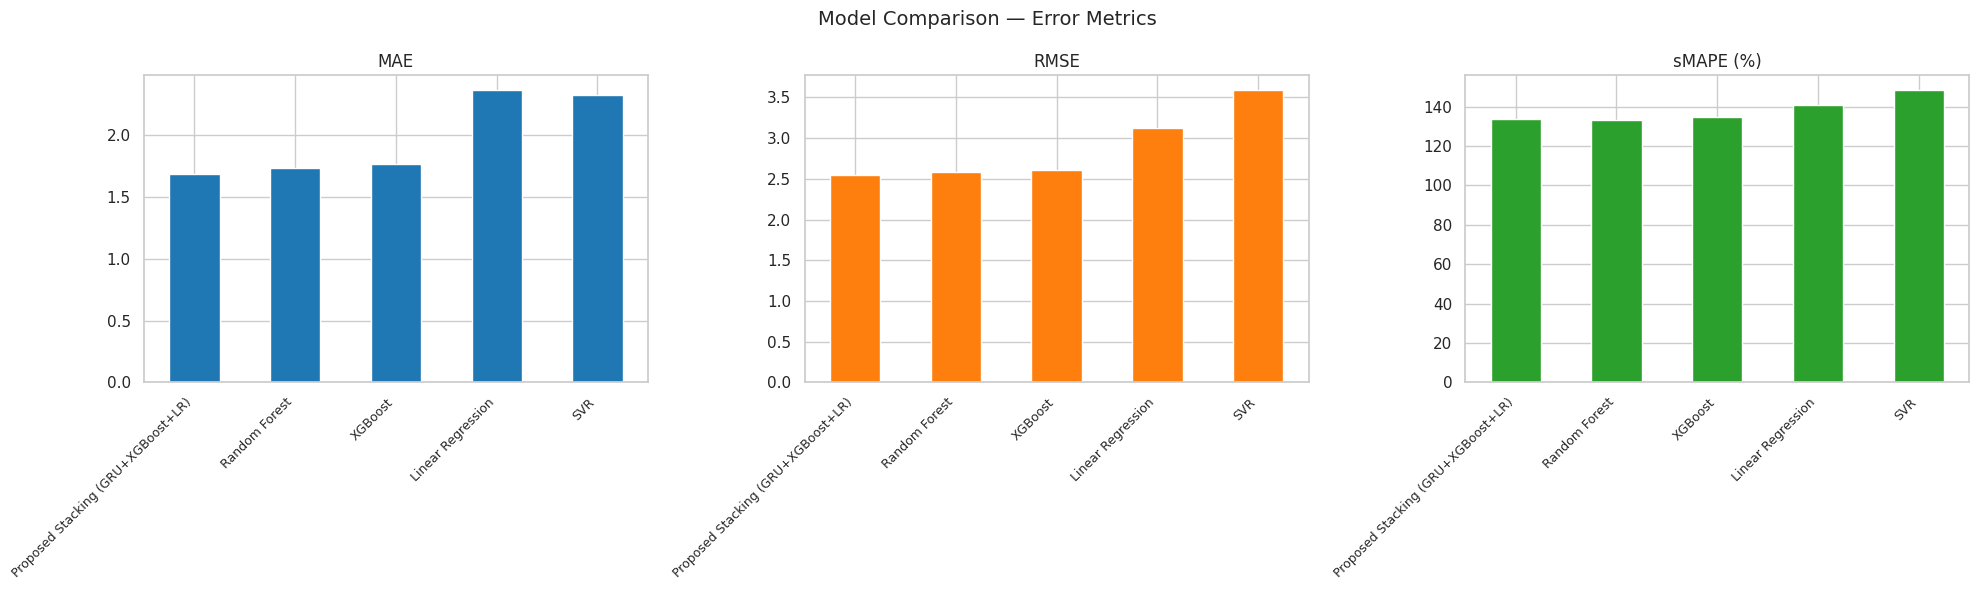

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20,6))

results_df.set_index('Model')['MAE'].plot(kind='bar', ax=axes[0], color='tab:blue')
axes[0].set_title('MAE')

results_df.set_index('Model')['RMSE'].plot(kind='bar', ax=axes[1], color='tab:orange')
axes[1].set_title('RMSE')

results_df.set_index('Model')['sMAPE'].plot(kind='bar', ax=axes[2], color='tab:green')
axes[2].set_title('sMAPE (%)')

for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
    for label in ax.get_xticklabels():
        label.set_ha('right')      # right-align so rotated text doesn't collide
        label.set_fontsize(9)

fig.suptitle('Model Comparison — Error Metrics', fontsize=14)
plt.tight_layout()
plt.show()

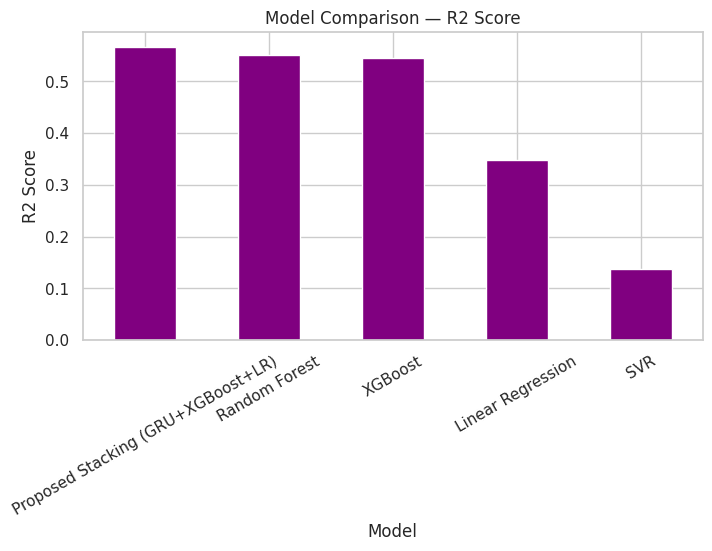

In [ ]:
results_df.set_index('Model')['R2'].plot(kind='bar', figsize=(8,4), color='purple')  # higher R2 = better fit
plt.ylabel("R2 Score")
plt.title("Model Comparison — R2 Score")
plt.xticks(rotation=30)
plt.show()


## 17. Actual vs Predicted — Proposed Model

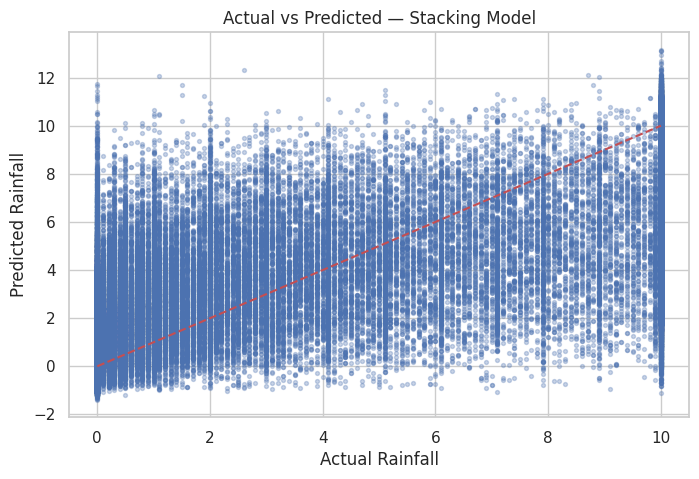

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, pred_stack, alpha=0.3, s=8)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # diagonal = perfect prediction line
plt.xlabel("Actual Rainfall")
plt.ylabel("Predicted Rainfall")
plt.title("Actual vs Predicted — Stacking Model")
plt.show()


## 18. Residual Analysis

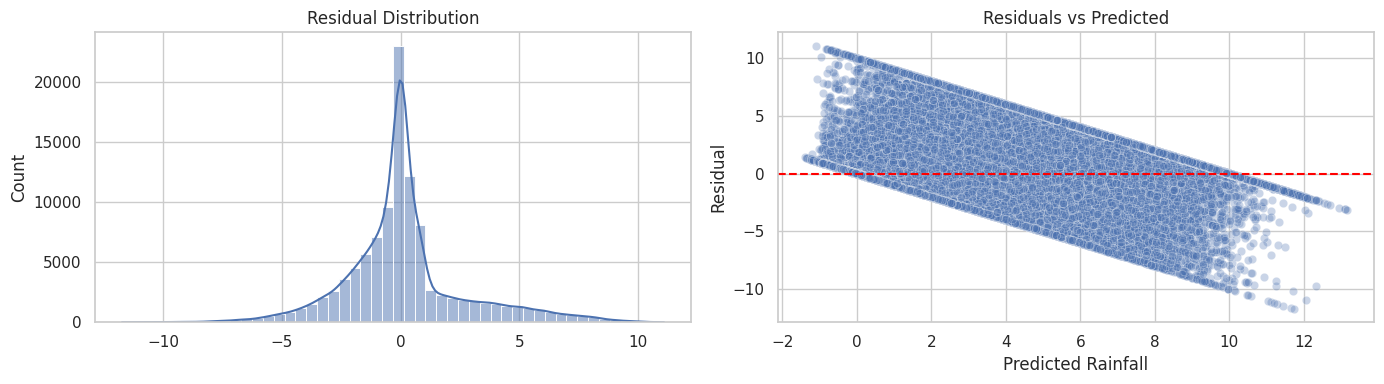

In [ ]:
residuals = y_test - pred_stack  # positive = under-prediction, negative = over-prediction

fig, axes = plt.subplots(1, 2, figsize=(14,4))
sns.histplot(residuals, bins=50, kde=True, ax=axes[0])
axes[0].set_title("Residual Distribution")
sns.scatterplot(x=pred_stack, y=residuals, alpha=0.3, ax=axes[1])
axes[1].axhline(0, color='red', linestyle='--')  # residual=0 reference line
axes[1].set_title("Residuals vs Predicted")
axes[1].set_xlabel("Predicted Rainfall")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.show()  # a random scatter around 0 with no funnel/curve shape indicates a good fit
